In [1]:
using LinearAlgebra
using Plots
using Printf

In [2]:
N = 400;

In [3]:
g, s = (2.5, 0.5);

In [4]:
function partially_hermitize(matrix, r)
    rabs = abs(r)
    if rabs == 0.0
        return matrix
    end
    return (
        sqrt((1 + sqrt(1 - rabs^2)) / 2) * matrix
        + (r / rabs) * sqrt((1 - sqrt(1 - rabs^2)) / 2) * matrix'
    )
end;

In [5]:
J = (g / sqrt(N)) * randn(N, N)

# Try (partially) symmetrizing the couplings. Symmetric couplings make the dynamics
# relaxational and preclude chaos near the zero fixed point.
rabs = 0.4
θ = pi / 3
r = rabs * exp(2im * θ)
J = partially_hermitize(J, r);

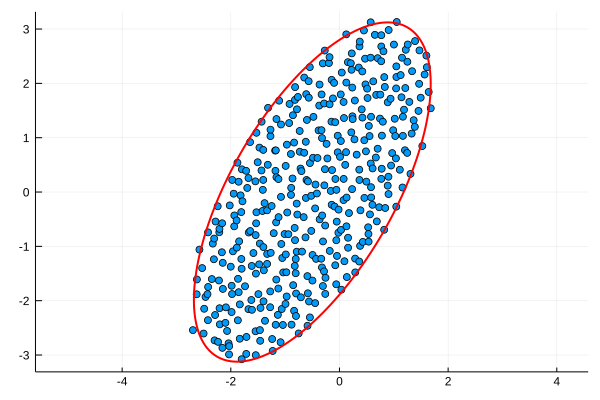

In [6]:
Jeff = J + s * I
evs = eigvals(Jeff - I)
a = g * (1 + rabs)
b = g * (1 - rabs)
scatter(real(evs), imag(evs), aspect_ratio=:equal, label="")
plot!(
    t -> a * cos(θ) * cos(t) - b * sin(θ) * sin(t) + (s - 1),
    t -> a * sin(θ) * cos(t) + b * cos(θ) * sin(t),
    0,
    2pi,
    label="",
    color=:red,
    linewidth=2,
) 

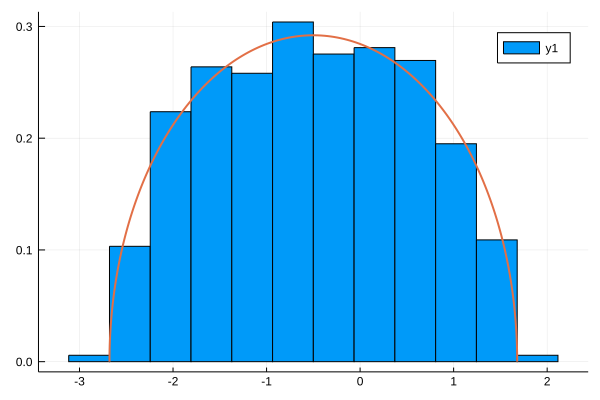

In [7]:
x = sqrt((a * cos(θ))^2 + (b * sin(θ))^2)
histogram(
    real(evs),
    bins=x * (-1.2:0.2:1.2) .+ (s - 1),
    normalize=:pdf,
)
plot!(
    t -> x * cos(t) + (s - 1),
    t -> sin(t) / (pi * x / 2),
    0,
    pi,
    label="",
    linewidth=2,
) 

In [8]:
# Alternative way to sample partially hermititian matrices for when the matrix is complex
function partially_hermitize2(matrix, r)
    rabs = abs(r)
    θ = angle(r) / 2
    phase = exp(im * θ)
    Mθ = matrix / phase
    MθR = (Mθ + Mθ') / 2
    MθI = (Mθ - Mθ') / 2im
    return phase * (sqrt(1 + rabs) * MθR + im * sqrt(1 - rabs) * MθI)
end;

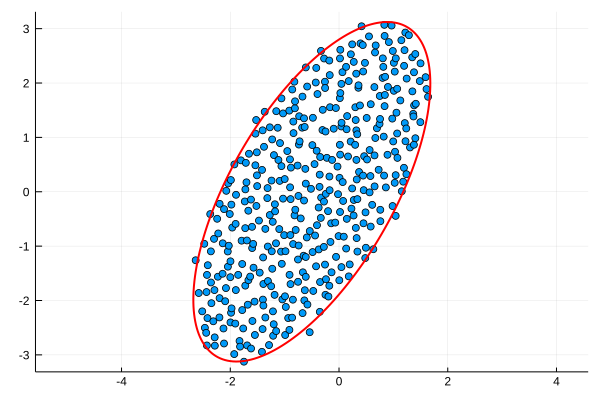

In [9]:
J = (g / sqrt(2N)) * (randn(N, N) + im * randn(N, N))
J = partially_hermitize2(J, r)
Jeff = J + s * I
evs = eigvals(Jeff - I)
scatter(real(evs), imag(evs), aspect_ratio=:equal, label="")
plot!(
    t -> a * cos(θ) * cos(t) - b * sin(θ) * sin(t) + (s - 1),
    t -> a * sin(θ) * cos(t) + b * cos(θ) * sin(t),
    0,
    2pi,
    label="",
    color=:red,
    linewidth=2,
)

In [10]:
# Verify moments
phase = exp(im * θ)
JR = (J + J') / 2
JI = (J - J') / 2im
Jθ = J / phase
JθR = (Jθ + Jθ') / 2
JθI = (Jθ - Jθ') / 2im

function parts(z)
    return real(z), imag(z)
end

@printf("%7.4f + i%7.4f\n", parts(sum(J .* conj.(J)) / (N * g^2))...)  # Variance
@printf("%7.4f + i%7.4f\n", parts(sum(J .* transpose(J)) / (N * g^2 * r))...)  # Transpose correlation
@printf("%7.4f + i%7.4f\n", parts(sum(JR .* transpose(JR)) / (N * g^2 * (1 - rabs * cos(θ)) / 2))...)  # Transpose correlation hermitian part
@printf("%7.4f + i%7.4f\n", parts(sum(JI .* transpose(JI)) / (N * g^2 * (1 + rabs * cos(θ)) / 2))...)  # Transpose correlation anithermitian part
@printf("%7.4f + i%7.4f\n", parts(sum(JR .* transpose(JI)) / (N * g^2 * rabs * sin(θ) / 2))...)  # Transpose hermitian-antihermitian cross correlation
@printf("%7.4f + i%7.4f\n", parts(sum(Jθ .* conj.(Jθ)) / (N * g^2))...)  # Rotated variance
@printf("%7.4f + i%7.4f\n", parts(sum(Jθ .* transpose(Jθ)) / (N * g^2 * rabs))...)  # Rotated transpose correlation
@printf("%7.4f + i%7.4f\n", parts(sum(JθR .* transpose(JθR)) / (N * g^2 * (1 + rabs) / 2))...)  # Rotated transpose correlation hermitian part
@printf("%7.4f + i%7.4f\n", parts(sum(JθI .* transpose(JθI)) / (N * g^2 * (1 - rabs) / 2))...)  # Rotated transpose correlation antihermitian part
@printf("%7.4f + i%7.4f\n", parts(sum(JθR .* transpose(JθI)) / (N * g^2 * rabs / 2))...)  # Should vanish: Rotated transpose hermitian-antihermitian cross correlation

 0.9999 + i 0.0000
 0.9931 + i-0.0008
 1.0020 + i 0.0000
 0.9986 + i 0.0000
 0.9936 + i 0.0000
 0.9999 + i 0.0000
 0.9931 + i-0.0008
 0.9980 + i 0.0000
 1.0045 + i 0.0000
-0.0008 + i-0.0000


In [11]:
# Find real and imaginary eigenvalue parts interpolating from antisymetric to symmetric
n = 20
matrix = (g / sqrt(n)) * randn(n, n)
rvals = -1:0.025:1
evals = complex(zeros(length(rvals), n))
for (i, r) in enumerate(rvals)
    pmatrix = partially_hermitize(matrix, r)
    pmatrix[diagind(pmatrix)] .= s
    evals[i, :] = eigvals(pmatrix - I)
end

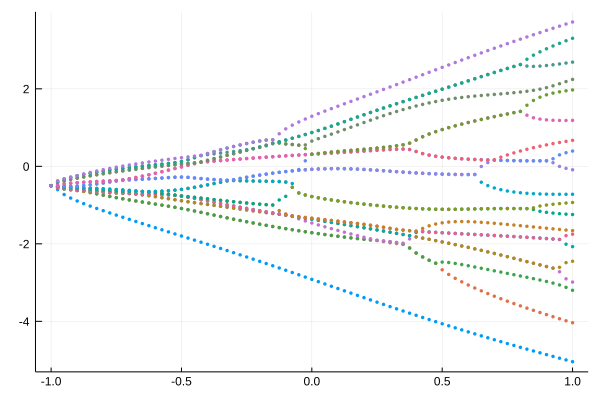

In [12]:
# Plot real part of eigenvalues
plot(
    rvals,
    real(evals),
    label="",
    linewidth=0,
    markershape=:circle,
    markersize=2,
    markerstrokewidth=0,
)

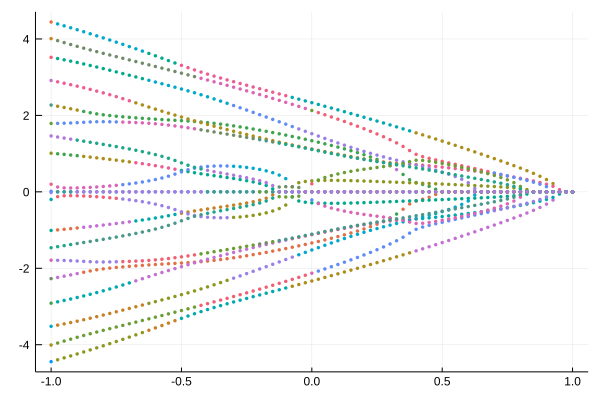

In [13]:
# Plot imaginary part of eigenvalues
plot(
    rvals,
    imag(evals),
    label="",
    linewidth=0,
    markershape=:circle,
    markersize=2,
    markerstrokewidth=0,
)